# 페르소나와 과업 제약

**이 노트북에서 할 일**

1. 페르소나 글 하나와 과업 명세 네 글(목표·필수 정보·금지 사항·출력 형식)을 따로 만듭니다.
2. 페르소나만 둔 목록과 과업 명세를 더한 목록을 같은 모델에 보내, 답 원문·토큰 수·줄 수를 비교합니다.
3. 과업 명세는 그대로 두고 페르소나 글만 바꿔, 페르소나가 바꾸는 것과 바꾸지 않는 것을 봅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 3번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

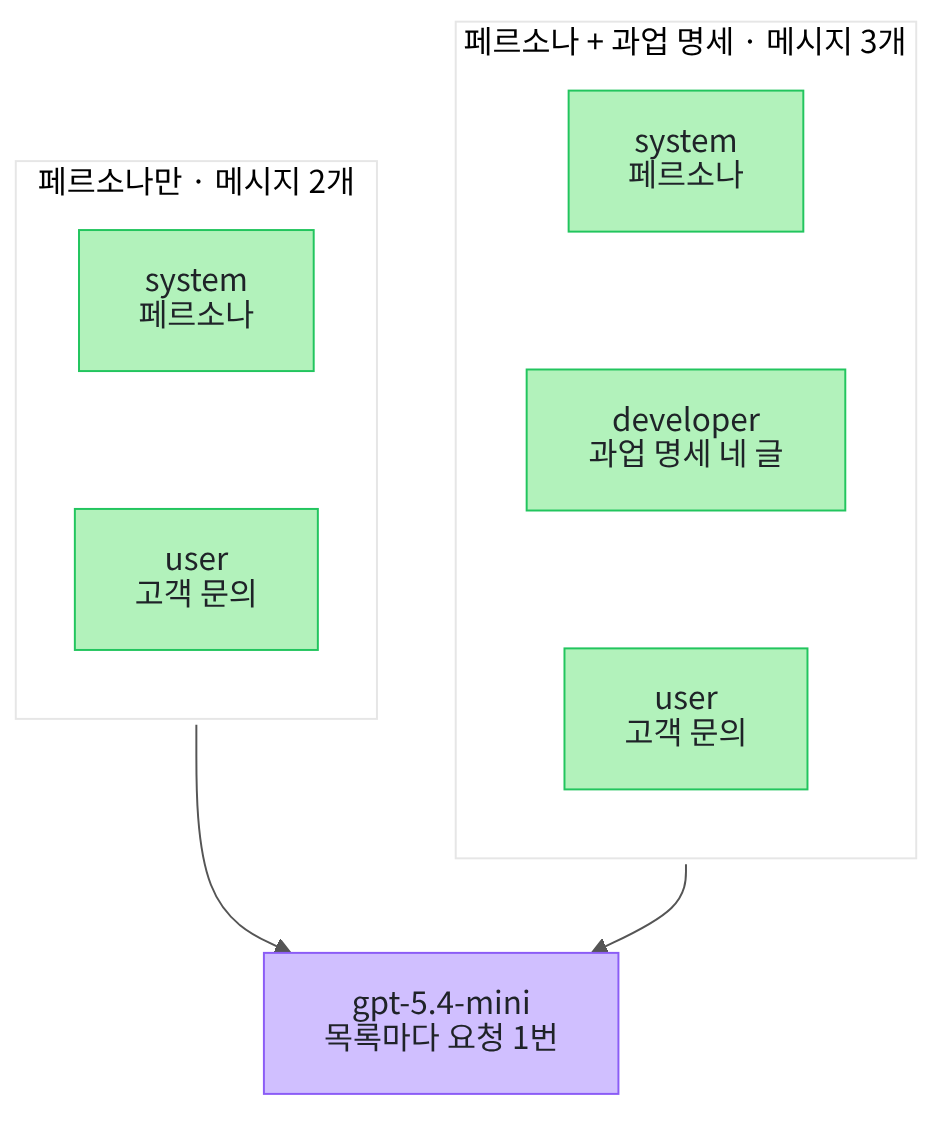

위에서 아래로 읽습니다. 왼쪽 칸은 페르소나 글과 고객 문의만 넣은 목록입니다.
오른쪽 칸은 같은 두 메시지 사이에 과업 명세를 developer 메시지로 더한 목록입니다.
두 목록은 아래 보라 상자의 같은 모델로 한 번씩 보냅니다. 다른 것은 developer 메시지 하나입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절과 같은 실습 폴더와 같은 판입니다. 노트북은 01절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

걸린 시간을 재는 모듈 `time`(Ch 6 05절)과 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 시간을 재는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import time

from langchain.chat_models import init_chat_model

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 페르소나 글과 고객 문의

페르소나(persona)는 모델이 답할 때 맡을 사람의 역할·말투·관점을 적은 글입니다.
가게 직원 명찰에 적힌 「친절 상담」 문구와 비슷합니다. 명찰은 태도를 알려 주지만, 교환 접수에 무엇이 필요한지는 알려 주지 않습니다.

이 셀은 페르소나 글과 고객 문의를 만듭니다. 고객 문의는 01절 `inquiry_text`와 글자까지 같습니다.

In [5]:
# 답할 사람의 역할과 말투를 적은 페르소나 글과, 01절과 같은 고객 문의를 만듭니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
print("페르소나:", persona_text)
print("고객 문의:", inquiry_text)

페르소나: 당신은 친절한 고객 상담원입니다.
고객 문의: 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.


**결과 읽기** — 두 줄은 `페르소나: 당신은 친절한 고객 상담원입니다.`와 `고객 문의:`로 시작하는 줄입니다.
페르소나 글에는 누구로서 답할지만 있고, 할 일이나 회사 규정은 없습니다.

## 3. 과업 명세 네 글 만들기

과업 명세(task specification)는 이번 답에서 할 일을 적은 글입니다. 이 절은 네 글로 나눠 적습니다.
목표는 무엇을 할지, 필수 정보는 답에 꼭 들어갈 내용, 금지 사항은 하면 안 되는 행동입니다. 출력 형식은 답을 늘어놓는 모양입니다.

01절 과업 제약은 금지 조건과 답의 세 부분이었습니다. 이 절은 거기에 목표와 필수 정보를 더합니다.
01절 공통 지시에 있던 규정 「회사 규정상 교환 접수에는 파손 사진이 필요합니다」는 필수 정보로 옮깁니다.

In [6]:
# 과업 명세를 목표·필수 정보·금지 사항·출력 형식 네 글로 나눠 만듭니다
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
print("목표:", goal_text)
print("필수 정보:", required_text)
print("금지 사항:", forbidden_text)
print("출력 형식:", format_text)

목표: 고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
필수 정보: 회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
금지 사항: 근거 없는 보상은 약속하지 마세요.
출력 형식: 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.


**결과 읽기** — 네 줄은 `목표:`, `필수 정보:`, `금지 사항:`, `출력 형식:`으로 시작합니다.
필수 정보 줄에는 01절에 없던 조건 `주문번호는 답에 그대로 적으세요.`가 있습니다. 01절에서 주문번호 표시가 실행마다 달랐기 때문에 더한 조건입니다.
출력 형식 줄의 「한 줄씩 세 줄」은 답에서 줄 수를 세어 확인할 수 있는 조건입니다.

이제 네 글을 줄바꿈 `"\n"`으로 이어 과업 명세 글 하나로 만듭니다. 01절에서 세 글을 이은 방법과 같습니다.

In [7]:
# 네 글을 줄바꿈으로 이어 과업 명세 글 하나로 만듭니다(요청은 보내지 않습니다)
task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + format_text
print("과업 명세:")
print(task_text)

과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.


**결과 읽기** — 라벨 줄 `과업 명세:` 아래 네 줄이 과업 명세 글 하나의 내용입니다.
첫 줄은 `고객 문의를 분류하고 필요한 다음 행동을 안내하세요.`, 마지막 줄은 출력 형식 문장입니다.

## 4. 두 목록 만들기

첫째 목록은 페르소나(system)와 고객 문의(user)만 넣습니다. 둘째 목록은 두 메시지 사이에 과업 명세를 developer 메시지로 넣습니다.
01절에서 과업 제약을 넣은 역할과 같은 자리입니다.

실행 전에 예상합니다. 메시지 수는 2와 3일 것입니다.

In [8]:
# 페르소나만 둔 목록과, 과업 명세를 developer 메시지로 더한 목록을 만듭니다(요청은 보내지 않습니다)
persona_messages = [
    ("system", persona_text),
    ("user", inquiry_text),
]
task_messages = [
    ("system", persona_text),
    ("developer", task_text),
    ("user", inquiry_text),
]
print("페르소나만 목록의 메시지 수:", len(persona_messages))
print("과업 명세 목록의 메시지 수:", len(task_messages))

페르소나만 목록의 메시지 수: 2
과업 명세 목록의 메시지 수: 3


**결과 읽기** — 두 줄은 `페르소나만 목록의 메시지 수: 2`와 `과업 명세 목록의 메시지 수: 3`입니다.

두 목록에서 다른 것은 developer 메시지 하나뿐이어야 합니다. 그래야 답이 달라졌을 때 과업 명세 때문이라고 좁혀 읽을 수 있습니다.
튜플도 연산자 `==`로 비교합니다. 두 튜플의 값이 순서대로 모두 같으면 `True`입니다.
같아야 하는 값이라 마지막 두 줄의 `assert`로 확인합니다.

In [9]:
# 두 목록의 system 메시지와 user 메시지가 같은지 확인합니다
same_system = persona_messages[0] == task_messages[0]
same_user = persona_messages[1] == task_messages[2]
print("system 메시지가 같은가:", same_system)
print("user 메시지가 같은가:", same_user)
assert same_system
assert same_user

system 메시지가 같은가: True
user 메시지가 같은가: True


**결과 읽기** — 두 줄은 `system 메시지가 같은가: True`와 `user 메시지가 같은가: True`입니다. `assert`도 통과했습니다.
이제 두 목록은 과업 명세 developer 메시지가 있는지만 다릅니다.

## 5. 두 목록을 같은 모델로 보내기

01절과 같은 함수 두 개로 요청마다 기록 한 줄을 만듭니다. 먼저 `timed_invoke()` 함수를 정의합니다.
Ch 6 06절과 같은 코드입니다. 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [10]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_prompt_record()`는 01절과 같은 코드입니다. 조건 이름·응답 객체·걸린 초로 딕셔너리 한 줄을 만듭니다.
키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [11]:
# 조건 이름·응답 객체·걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_prompt_record(condition, run_response, run_elapsed):
    run_usage = run_response.usage_metadata
    record = {
        "조건": condition,
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 이제 두 함수를 부릅니다.

페르소나만 둔 목록을 먼저 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.
실행 전에 예상합니다. 모델은 회사 규정을 모릅니다. 사진을 요청할까요, 세 줄로 답할까요?

In [12]:
# 페르소나만 둔 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
persona_response, persona_elapsed = timed_invoke(model, persona_messages)
persona_record = make_prompt_record("페르소나만", persona_response, persona_elapsed)
print("답:")
print(persona_record["답"])

답:
불편을 드려 죄송합니다. 주문번호 **A-1042** 확인했습니다.  
뚜껑이 깨진 경우 **교환**으로 진행 도와드릴 수 있습니다.

진행을 위해 아래 정보가 필요합니다:
1. **파손된 뚜껑 사진**
2. **주문자 성함**
3. **연락처**
4. **교환받을 주소**가 동일한지 여부

사진과 함께 보내주시면 바로 교환 접수 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `불편을 드려 죄송합니다.`로 시작하고, 주문번호를 `**A-1042**`처럼 굵은 글씨 표시로 적었습니다.
가운데에는 `진행을 위해 아래 정보가 필요합니다:` 아래로 번호 목록 네 줄이 있습니다.
목록은 `파손된 뚜껑 사진`, `주문자 성함`, `연락처`, 교환받을 주소입니다. 보상 약속은 없었습니다.

사진은 회사 규정을 받지 않고도 요청했습니다. 성함·연락처·주소는 이 절의 회사 규정에 적지 않은 정보입니다.
페르소나만으로는 무엇을 요청할지를 모델이 스스로 정했습니다. 답 모양도 세 줄이 아니라 빈 줄이 든 긴 목록이었습니다.

이번에는 과업 명세를 더한 목록을 같은 모델로 보냅니다. 바꾼 것은 넘기는 목록 하나입니다.
실행 전에 예상합니다. 출력 형식대로 분류·다음 행동·고객 문장 세 줄이 나올 것입니다.

In [13]:
# 과업 명세를 더한 목록을 같은 모델로 보내고 기록 한 줄을 만듭니다(요청 1번)
task_response, task_elapsed = timed_invoke(model, task_messages)
task_record = make_prompt_record("페르소나 + 과업 명세", task_response, task_elapsed)
print("답:")
print(task_record["답"])

답:
분류: 교환 요청(파손)
다음 행동: 파손 사진을 보내주시면 교환 접수를 도와드리겠습니다. 주문번호 A-1042 확인했습니다.
고객에게 보낼 한 문장: 어제 받으신 텀블러 뚜껑 파손 건은 주문번호 A-1042로 확인되며, 교환 접수를 위해 파손 사진을 보내주시면 바로 안내드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 요청(파손)`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄과 고객 문장 줄에 `A-1042`가 있습니다. 다음 행동 줄은 `파손 사진을 보내주시면 교환 접수를 도와드리겠습니다.`로 시작합니다.
성함·연락처·주소 요청과 굵은 글씨 표시는 없었고, 보상 약속도 없었습니다.

## 6. 기록표로 비교하기

두 기록을 01절과 같은 기록표 모양으로 출력합니다. 마지막 줄은 과업 명세가 더한 입력 토큰 수입니다.
실행 전에 예상합니다. 과업 명세 네 문장만큼 입력 토큰이 늘 것입니다. 출력 토큰은 늘까요, 줄까요?

In [14]:
# 두 기록을 목록에 담고 한 줄에 한 조건씩 출력합니다
records = [persona_record, task_record]
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
input_difference = task_record["입력 토큰 수"] - persona_record["입력 토큰 수"]
print("과업 명세가 더한 입력 토큰 수:", input_difference)

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
페르소나만 | 56 | 117 | stop | 1.14
페르소나 + 과업 명세 | 134 | 99 | stop | 1.19
과업 명세가 더한 입력 토큰 수: 78


**결과 읽기** — 라벨 줄 아래 두 줄은 `페르소나만 | 56 | 117 | stop | 1.14`와 `페르소나 + 과업 명세 | 134 | 99 | stop | 1.19`입니다.
마지막 줄은 `과업 명세가 더한 입력 토큰 수: 78`입니다. 과업 명세 네 문장이 입력 토큰을 78개 더했습니다.

출력 토큰은 117에서 99로 줄었습니다. 입력과 출력을 더하면 페르소나만 173, 과업 명세 233이라 요청 전체로는 과업 명세 쪽이 많습니다.
걸린 초 1.14와 1.19는 한 번씩 잰 값이라 속도 순위로 읽지 않습니다. 교재를 만들 때 앞선 새 커널 실행에서는 1.92초와 1.11초였습니다.

## 7. 확인할 수 있는 조건 세어 보기

출력 형식 「한 줄씩 세 줄」은 코드로 셀 수 있는 조건입니다. 글의 메서드 `split("\n")`은 줄바꿈 자리에서 글을 잘라 목록으로 반환합니다.
함수 `len()`은 Part 1에서 목록 길이를 셀 때 썼습니다. 글에 쓰면 글자 수를 셉니다.

빈 줄도 한 줄로 셉니다. 「세 줄로 답하세요」에는 빈 줄을 넣지 말라는 뜻도 들어 있다고 보기 때문입니다.
실행 전에 예상합니다. 과업 명세 답의 줄 수는 3일 것입니다.

In [15]:
# 두 답의 글자 수와 줄 수(빈 줄 포함)를 셉니다
print("조건 | 글자 수 | 줄 수(빈 줄 포함)")
for record in records:
    answer_length = len(record["답"])
    answer_lines = record["답"].split("\n")
    line_count = len(answer_lines)
    print(record["조건"], "|", answer_length, "|", line_count)

조건 | 글자 수 | 줄 수(빈 줄 포함)
페르소나만 | 195 | 10
페르소나 + 과업 명세 | 159 | 3


**결과 읽기** — 라벨 줄 아래 두 줄은 `페르소나만 | 195 | 10`과 `페르소나 + 과업 명세 | 159 | 3`입니다.
과업 명세 답은 출력 형식대로 세 줄이었습니다. 페르소나만 둔 답은 빈 줄 두 개를 포함해 10줄이었습니다.

줄 수는 원문을 읽지 않고도 코드로 확인할 수 있는 조건입니다. 다만 줄 수 3이 세 줄에 알맞은 내용이 들어갔다는 뜻은 아닙니다.
각 줄의 내용은 5절에서 원문을 읽어 확인했습니다.

필수 정보에 적은 주문번호와 사진, 분류 낱말 교환이 답에 있는지도 표시합니다. 01절과 같은 확인 단어 세 개입니다.
이 표시는 품질 점수가 아니라, 원문에서 읽을 곳을 찾는 도구입니다.

In [16]:
# 확인 단어 세 개가 두 답에 들어 있는지 표시합니다(품질 점수가 아니라, 원문에서 읽을 곳 표시)
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | 페르소나만 답에 있는가 | 과업 명세 답에 있는가")
for word in check_words:
    in_persona = word in persona_record["답"]
    in_task = word in task_record["답"]
    print(word, "|", in_persona, "|", in_task)

확인 단어 | 페르소나만 답에 있는가 | 과업 명세 답에 있는가
교환 | True | True
A-1042 | True | True
사진 | True | True


**결과 읽기** — 라벨 줄 아래 세 줄 `교환`, `A-1042`, `사진`은 모두 `True | True`로 끝납니다. 확인 단어 세 개가 두 답에 모두 있었습니다.
확인 단어 표시로는 두 조건의 차이를 찾지 못했습니다. 차이는 줄 수와, 규정에 없는 성함·연락처·주소 요청에서 보였습니다.

페르소나만 둔 답의 사진 표시 `True`도 규정을 따른 결과가 아닙니다. 그 목록에는 회사 규정이 없었으므로, 모델이 스스로 고른 요청입니다.

## 8. 값 바꿔 보기 — 페르소나 글만 바꾸기

바꾸는 값은 `persona_text` 자리의 글 하나입니다. 「친절한 고객 상담원」을 「말수가 적고 사무적인 고객 상담원」으로 바꿉니다.
과업 명세와 고객 문의는 그대로 둡니다. 이 셀은 목록만 만들고 요청을 보내지 않습니다.

실행 전에 예상합니다. 말투는 달라지고, 세 줄 모양과 주문번호는 그대로일까요?

In [17]:
# 페르소나 글만 바꾸고 과업 명세·고객 문의는 그대로 둔 목록을 만듭니다(요청은 보내지 않습니다)
plain_persona_text = "당신은 말수가 적고 사무적인 고객 상담원입니다."
plain_messages = [
    ("system", plain_persona_text),
    ("developer", task_text),
    ("user", inquiry_text),
]
print("바꾼 페르소나:", plain_messages[0][1])

바꾼 페르소나: 당신은 말수가 적고 사무적인 고객 상담원입니다.


**결과 읽기** — 출력 줄은 `바꾼 페르소나: 당신은 말수가 적고 사무적인 고객 상담원입니다.`입니다.
developer 메시지와 user 메시지는 5절에서 보낸 과업 명세 목록과 같은 변수를 썼습니다.

바꾼 목록을 보냅니다.

In [18]:
# 페르소나만 바꾼 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
plain_response, plain_elapsed = timed_invoke(model, plain_messages)
plain_record = make_prompt_record("사무적 페르소나 + 과업 명세", plain_response, plain_elapsed)
print("답:")
print(plain_record["답"])

답:
분류: 교환 접수  
다음 행동: 파손 부위가 보이도록 사진을 보내주시면 교환 가능 여부를 확인해 접수하겠습니다. 주문번호 A-1042  
고객에게 보낼 한 문장: 파손 사진을 보내주시면 주문번호 A-1042 기준으로 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 접수`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄은 `교환 가능 여부를 확인해 접수하겠습니다.`로 문장을 맺고, 뒤에 `주문번호 A-1042`만 따로 붙였습니다.

5절 과업 명세 답의 「교환 접수를 도와드리겠습니다」보다 짧게 끊은 말투입니다. 고객 문장 줄은 두 답 모두 「도와드리겠습니다」로 끝났습니다.
세 줄 모양, 주문번호, 사진 요청은 그대로였고 보상 약속도 없었습니다.

과업 명세를 둔 두 기록을 나란히 봅니다. 토큰 수와 글자 수, 줄 수, 주문번호 표시를 한 줄에 출력합니다.

In [19]:
# 과업 명세를 둔 두 기록을 토큰 수·글자 수·줄 수·주문번호 표시로 나란히 봅니다
persona_pair = [task_record, plain_record]
print("조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수 | 줄 수 | A-1042")
for record in persona_pair:
    answer_length = len(record["답"])
    answer_lines = record["답"].split("\n")
    has_order = "A-1042" in record["답"]
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", answer_length, "|", len(answer_lines), "|", has_order)

조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수 | 줄 수 | A-1042
페르소나 + 과업 명세 | 134 | 99 | 159 | 3 | True
사무적 페르소나 + 과업 명세 | 138 | 81 | 138 | 3 | True


**결과 읽기** — 라벨 줄 아래 두 줄은 `페르소나 + 과업 명세 | 134 | 99 | 159 | 3 | True`와 `사무적 페르소나 + 과업 명세 | 138 | 81 | 138 | 3 | True`입니다.
페르소나 글이 조금 길어져 입력 토큰은 4개 늘었고, 출력 토큰은 99에서 81로 줄었습니다.
사무적 답의 글자 수에는 첫 두 줄 끝에 붙은 보이지 않는 공백 두 칸씩도 들어 있습니다.

줄 수 3과 주문번호 표시 `True`는 두 페르소나가 같았습니다. 이번 실행에서 페르소나 글은 답의 길이와 낱말을 조금 바꿨습니다.
과업 명세가 정한 세 줄 모양과 필수 정보는 바꾸지 않았습니다. 앞선 새 커널 실행에서도 출력 토큰은 89와 80, 줄 수는 3과 3이었습니다.

## 실험 결과 해석

이번 실행에서 페르소나만 둔 답은 친절한 말투였지만 세 줄 형식이 아니었습니다. 회사 규정에 없는 성함·연락처·주소도 요청했습니다.
과업 명세를 더한 답은 세 줄에 주문번호와 사진 요청을 담았습니다. 두 답 모두 보상 약속은 없었습니다.

과업 명세는 입력 토큰을 78개 더했고, 답을 코드로 확인할 수 있는 모양(줄 수 3)으로 만들었습니다.
페르소나 글만 바꾸면 답의 길이와 낱말이 조금 달라졌고, 세 줄 모양과 주문번호는 그대로였습니다.
이 결론은 고객 문의 하나·모델 하나·설정마다 한 번 실행한 범위입니다. 페르소나가 답의 정확성을 높이는지는 이번에 확인하지 않았습니다.

## 정리

- 페르소나는 누구로서 답할지를 정하는 글이고, 할 일·규정·형식은 과업 명세 네 글로 따로 적었습니다.
- 과업 명세를 developer 메시지로 더하자 답이 세 줄이 됐고, 입력 토큰은 78개 늘었습니다.
- 확인 단어 표시로는 차이가 보이지 않아, 줄 수 세기와 원문 읽기로 차이를 찾았습니다.

다음 03절에서는 형식 지시는 그대로 두고, 다른 고객 문의와 답으로 된 예시를 더해 비교합니다. 고객 문의는 이 절과 같습니다.